# Cross-dataset · train TexMM → test Microscope (DenseNet-121, LAMB)

Train on the source dataset(s) with the LAMB recipe (ImageNet-pretrained, end-to-end, **unweighted** BCE)
and evaluate on the entirely unseen **Microscope** dataset using the harmonised class set (intersection of the
per-dataset classes; Elastane=Spandex, Viscose=Rayon, Polyamide=Nylon). An internal 80/20 split of the
training data is used for early stopping; Microscope is never seen during training.


## 1 · Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


## 2 · Configuration

In [ ]:
# ===== CONFIG  (edit these to complete / tweak the report settings) =====
RANDOM_SEED = 42
IMG_SIZE = 448
BATCH_SIZE = 16
NUM_WORKERS = 2
THRESHOLD = 0.5
USE_SSD = True
BACKBONE = 'densenet121'
REGIME = 'transfer'
WEIGHTED = False
AUGMENT = False
LR = 0.001
WEIGHT_DECAY = 0.01
EPOCHS = 40
EARLY_STOP_PATIENCE = 10
VAL_SPLIT = 0.2
CROP_SCALE = (0.6, 1.0)
CROP_RATIO = (0.9, 1.1)
ROTATION_DEG = 15
CONTRAST_JITTER = 0.2
SATURATION_JITTER = 0.2
GAUSSIAN_NOISE_STD = 0.01
TRAIN_DATASETS = ['texmm']
TEST_DATASET = 'micro'
RUN_NAME = 'CROSS TexMM -> Microscope | DenseNet-121 | LAMB'
RUN_TAG = 'cross_texmm_to_micro_densenet121_hires448_cosine'
CKPT_PATH = '/content/cross_texmm_to_micro_densenet121_hires448_cosine.pt'
SAVE_DIR = '/content/drive/MyDrive/Microscope_Images_Dataset'
DRIVE_TEXMM = '/content/drive/MyDrive/TexMM_Local'
DRIVE_MICRO = '/content/drive/MyDrive/Microscope_Images_Dataset'

## 3 · Imports, seeds, device

In [ ]:
import os, re, math, random, shutil, time, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             accuracy_score, hamming_loss, classification_report)

random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED); torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, (torch.cuda.get_device_name(0) if DEVICE == 'cuda' else ''))

Device: cuda NVIDIA A100-SXM4-40GB


## 4 · Copy datasets to local SSD

In [ ]:
def copy_to_ssd(src, dst, workers=64):
    '''Copy a Drive folder to the local Colab NVMe once (skips already-copied files).'''
    if not os.path.isdir(src):
        raise FileNotFoundError(
            'Drive source not found: ' + src +
            '\nIf the folder is under "Shared with me", right-click it -> '
            'Add shortcut to Drive -> My Drive, then fix the path in CONFIG.')
    for root, _, _ in os.walk(src):
        os.makedirs(root.replace(src, dst, 1), exist_ok=True)
    files = [(os.path.join(r, f), os.path.join(r, f).replace(src, dst, 1))
             for r, _, fs in os.walk(src) for f in fs]
    todo = [(s, d) for s, d in files if not os.path.exists(d)]
    print(f'{src} -> {dst} | total {len(files)} | to copy {len(todo)}')

    def _one(a):
        s, d = a
        for k in range(4):
            try:
                shutil.copy2(s, d); return True
            except OSError as e:
                if k == 3:
                    return f'FAIL {os.path.basename(s)} [{e}]'
                time.sleep(3)

    t0 = time.time(); ok = bad = 0
    with ThreadPoolExecutor(max_workers=workers) as ex:
        for i, fut in enumerate(as_completed([ex.submit(_one, x) for x in todo])):
            r = fut.result()
            if r is True: ok += 1
            else: bad += 1; print('  ', r)
            if (i + 1) % 500 == 0:
                print(f'  {i+1}/{len(todo)}  ok={ok} bad={bad}')
    print(f'done in {(time.time()-t0)/60:.1f} min | ok={ok} bad={bad}')
    return dst

## 5 · Load datasets & harmonise classes

In [ ]:
# Canonical fibre ordering + report equivalences (Elastane=Spandex, Viscose=Rayon, Polyamide=Nylon).
CANON_ORDER = ['Spandex','Cashmere','Linen','Rayon','Modal','Tencel','Polyester','Wool',
               'Nylon','Acrylic','Silk','Cotton','Hemp','PLA','Alpaca','Peat']

CODE_MAP = {'SP':'Spandex','CA':'Cashmere','L':'Linen','R':'Rayon','M':'Modal','TEN':'Tencel',
            'P':'Polyester','W':'Wool','N':'Nylon','A':'Acrylic','S':'Silk','C':'Cotton'}

MICRO_MAP = {'Cotton':'Cotton','Wool':'Wool','Hemp':'Hemp','Linen':'Linen','Elastane':'Spandex',
             'Polyester':'Polyester','Viscose':'Rayon','Silk':'Silk','Tencel':'Tencel','PLA':'PLA',
             'Polyamide':'Nylon','Alpaca':'Alpaca','Peat fibre':'Peat'}

def _read_texmm():
    base = copy_to_ssd(DRIVE_TEXMM, '/content/TexMM_Local') if USE_SSD else DRIVE_TEXMM
    ys = list(np.load(os.path.join(base, 'train_y.npy')).max(1)) + \
         list(np.load(os.path.join(base, 'test_y.npy')).max(1))
    def _p(csv):
        raw = open(os.path.join(base, csv)).read()
        return [p.strip().lstrip('./') for p in raw.split(',') if p.strip()]
    paths = _p('train_direct_list.csv') + _p('test_direct_list.csv')
    codes = ['SP','CA','L','R','M','TEN','P','W','N','A','S','C']
    recs = []
    for rp, l in zip(paths, ys):
        ip = os.path.join(base, rp)
        if not os.path.isfile(ip): continue
        sid = 'TEXMM__' + re.sub(r'\(\d+\)\.[^/]+$', '', rp)
        canon = frozenset(CODE_MAP[codes[i]] for i in range(len(codes)) if l[i] > 0)
        recs.append((ip, canon, sid))
    vocab = set().union(*[c for _, c, _ in recs]) if recs else set()
    print(f'TexMM: {len(recs)} images | vocab {sorted(vocab)}')
    return recs, vocab

def _read_micro():
    base = copy_to_ssd(DRIVE_MICRO, '/content/Microscope_Local') if USE_SSD else DRIVE_MICRO
    cls = list(MICRO_MAP.keys())
    dfm = pd.read_excel(os.path.join(base, 'LabelsMatrix.xlsx'), sheet_name=0)
    dfm['key'] = dfm['Name'].astype(str).str.lower().str.strip()
    for c in cls: dfm[c] = dfm[c].fillna(0).astype(int)
    look = dfm.set_index('key')[cls].to_dict('index')
    s2i = defaultdict(list)
    for p in sorted(Path(os.path.join(base, 'Images')).glob('*.jpg')):
        sid = re.sub(r'_\d+$', '', p.stem).lower()
        if sid in look: s2i[sid].append(str(p))
    recs = []
    for sid in [s for s in dfm['key'] if s in s2i]:
        canon = frozenset(MICRO_MAP[c] for c in cls if look[sid][c] > 0)
        for pth in s2i[sid]:
            recs.append((pth, canon, 'MICRO__' + str(sid)))
    vocab = set().union(*[c for _, c, _ in recs]) if recs else set()
    print(f'Microscope: {len(recs)} images | vocab {sorted(vocab)}')
    return recs, vocab

READERS = {'texmm': _read_texmm, 'micro': _read_micro}

cache = {d: READERS[d]() for d in dict.fromkeys(list(TRAIN_DATASETS) + [TEST_DATASET])}

train_canon, train_vocab = [], set()
for d in TRAIN_DATASETS:
    r, v = cache[d]; train_canon += r; train_vocab |= v
test_canon, test_vocab = cache[TEST_DATASET]

CLASSES = [c for c in CANON_ORDER if c in (train_vocab & test_vocab)]
NUM_CLASSES = len(CLASSES)
print(f'\nHarmonised classes ({NUM_CLASSES}): {CLASSES}')

def _vec(canon): return np.array([1.0 if c in canon else 0.0 for c in CLASSES], dtype=np.float32)
train_full = [(p, _vec(c), s) for (p, c, s) in train_canon]
test_records = [(p, _vec(c), s) for (p, c, s) in test_canon]

# internal sample-level split of the training data for early stopping / checkpointing
tr_sids = sorted({s for _, _, s in train_full})
tr_keep, _ = train_test_split(tr_sids, test_size=VAL_SPLIT, random_state=RANDOM_SEED, shuffle=True)
tr_keep = set(tr_keep)
train_records = [r for r in train_full if r[2] in tr_keep]
val_records   = [r for r in train_full if r[2] not in tr_keep]
print(f'train {len(train_records)} imgs | val {len(val_records)} imgs | test {len(test_records)} imgs')

/content/drive/MyDrive/TexMM_Local -> /content/TexMM_Local | total 9203 | to copy 9203
  500/9203  ok=500 bad=0
  1000/9203  ok=1000 bad=0
  1500/9203  ok=1500 bad=0
  2000/9203  ok=2000 bad=0
  2500/9203  ok=2500 bad=0
  3000/9203  ok=3000 bad=0
  3500/9203  ok=3500 bad=0
  4000/9203  ok=4000 bad=0
  4500/9203  ok=4500 bad=0
  5000/9203  ok=5000 bad=0
  5500/9203  ok=5500 bad=0
  6000/9203  ok=6000 bad=0
  6500/9203  ok=6500 bad=0
  7000/9203  ok=7000 bad=0
  7500/9203  ok=7500 bad=0
  8000/9203  ok=8000 bad=0
  8500/9203  ok=8500 bad=0
  9000/9203  ok=9000 bad=0
done in 4.2 min | ok=9203 bad=0
TexMM: 8541 images | vocab ['Acrylic', 'Cashmere', 'Cotton', 'Linen', 'Modal', 'Nylon', 'Polyester', 'Rayon', 'Silk', 'Spandex', 'Tencel', 'Wool']
/content/drive/MyDrive/Microscope_Images_Dataset -> /content/Microscope_Local | total 2214 | to copy 2214
  500/2214  ok=500 bad=0
  1000/2214  ok=1000 bad=0
  1500/2214  ok=1500 bad=0
  2000/2214  ok=2000 bad=0
done in 4.2 min | ok=2214 bad=0
Micros

## 6 · Transforms & DataLoaders

In [ ]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

class AddGaussianNoise:
    def __init__(self, std=0.01): self.std = std
    def __call__(self, t): return t + torch.randn_like(t) * self.std

eval_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])

if AUGMENT:
    train_tf = T.Compose([
        T.RandomResizedCrop(IMG_SIZE, scale=CROP_SCALE, ratio=CROP_RATIO),
        T.RandomHorizontalFlip(),
        T.RandomVerticalFlip(),
        T.RandomRotation(ROTATION_DEG),
        T.ColorJitter(contrast=CONTRAST_JITTER, saturation=SATURATION_JITTER),
        T.ToTensor(), T.Normalize(MEAN, STD), AddGaussianNoise(GAUSSIAN_NOISE_STD),
    ])
else:
    train_tf = eval_tf

class TextileDataset(Dataset):
    def __init__(self, records, tf): self.records = records; self.tf = tf
    def __len__(self): return len(self.records)
    def __getitem__(self, i):
        p, l, s = self.records[i]
        return self.tf(Image.open(p).convert('RGB')), torch.tensor(l, dtype=torch.float32), s

train_loader = DataLoader(TextileDataset(train_records, train_tf), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(TextileDataset(val_records, eval_tf), batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

eval_loader = DataLoader(TextileDataset(test_records, eval_tf), batch_size=BATCH_SIZE,
                         shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
print(f'Batches | train {len(train_loader)} | val {len(val_loader)} | test {len(eval_loader)}')

Batches | train 428 | val 107 | test 138


## 7 · Model (ImageNet-pretrained)

In [ ]:
def build_backbone(name, pretrained):
    name = name.lower()
    if name == 'resnet50':
        w = models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
        net = models.resnet50(weights=w); in_f = net.fc.in_features; net.fc = nn.Identity()
    elif name == 'vgg19':
        w = models.VGG19_Weights.IMAGENET1K_V1 if pretrained else None
        net = models.vgg19(weights=w); in_f = net.classifier[0].in_features; net.classifier = nn.Identity()
    elif name == 'densenet121':
        w = models.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None
        net = models.densenet121(weights=w); in_f = net.classifier.in_features; net.classifier = nn.Identity()
    elif name == 'efficientnet_b0':
        w = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        net = models.efficientnet_b0(weights=w); in_f = net.classifier[1].in_features; net.classifier = nn.Identity()
    else:
        raise ValueError('Unknown BACKBONE: ' + name)
    return net, in_f

class TextileCNN(nn.Module):
    def __init__(self, backbone_name, num_classes, pretrained):
        super().__init__()
        self.backbone, in_f = build_backbone(backbone_name, pretrained)
        self.classifier = nn.Sequential(
            nn.Dropout(0.3), nn.Linear(in_f, 512), nn.ReLU(inplace=True),
            nn.Dropout(0.2), nn.Linear(512, num_classes))
    def forward(self, x): return self.classifier(self.backbone(x))
    def set_backbone_trainable(self, flag):
        for p in self.backbone.parameters(): p.requires_grad = flag

PRETRAINED = (REGIME == 'transfer')
model = TextileCNN(BACKBONE, NUM_CLASSES, PRETRAINED).to(DEVICE)
print(f'{BACKBONE} | {sum(p.numel() for p in model.parameters()):,} params | '
      f'regime={REGIME} | pretrained={PRETRAINED}')

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 238MB/s]


densenet121 | 7,483,273 params | regime=transfer | pretrained=True


## 8 · Loss

In [ ]:
# Paper uses a plain (unweighted) multi-label BCE -- eq. (11).
criterion = nn.BCEWithLogitsLoss()
print('Loss: unweighted BCEWithLogits (paper recipe)')

Loss: unweighted BCEWithLogits (paper recipe)


## 9 · Optimiser (LAMB)

In [ ]:
class Lamb(torch.optim.Optimizer):
    '''Minimal LAMB optimiser (You et al., 2019) -- the optimiser used in the TexMM paper.
    LAMB = Adam moments + decoupled weight decay + per-layer trust-ratio scaling.'''
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-6, weight_decay=0.01):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))
    @torch.no_grad()
    def step(self, closure=None):
        loss = closure() if closure is not None else None
        for grp in self.param_groups:
            b1, b2 = grp['betas']
            for p in grp['params']:
                if p.grad is None: continue
                g, st = p.grad, self.state[p]
                if not st:
                    st['step'] = 0; st['m'] = torch.zeros_like(p); st['v'] = torch.zeros_like(p)
                st['step'] += 1
                st['m'].mul_(b1).add_(g, alpha=1 - b1)
                st['v'].mul_(b2).addcmul_(g, g, value=1 - b2)
                mhat = st['m'] / (1 - b1 ** st['step'])
                vhat = st['v'] / (1 - b2 ** st['step'])
                upd = mhat / (vhat.sqrt() + grp['eps'])
                if grp['weight_decay'] != 0:
                    upd = upd.add(p, alpha=grp['weight_decay'])
                wn, un = p.norm(), upd.norm()
                trust = (wn / un).item() if (wn > 0 and un > 0) else 1.0
                p.add_(upd, alpha=-grp['lr'] * trust)
        return loss

## 10 · Training (train on source, early-stop on internal split)

In [ ]:
def exact_match(L, P): return float(np.all(L == P, axis=1).mean())

def run_epoch(loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    tot, Ps, Ls = 0.0, [], []
    with torch.set_grad_enabled(train):
        for imgs, labels, _ in loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            logits = model(imgs); loss = criterion(logits, labels)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            tot += loss.item() * len(imgs)
            Ps.append((torch.sigmoid(logits) > THRESHOLD).cpu().numpy().astype(int))
            Ls.append(labels.cpu().numpy().astype(int))
    P, L = np.vstack(Ps), np.vstack(Ls)
    return tot / len(loader.dataset), exact_match(L, P), f1_score(L, P, average='micro', zero_division=0)

# ImageNet-pretrained backbone fine-tuned END-TO-END with LAMB + CosineAnnealingLR (no restarts),
# unweighted BCE. Best checkpoint by validation subset accuracy.
ETA_MIN = 1e-6
model.set_backbone_trainable(True)
opt = Lamb(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=ETA_MIN)
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'train_f1': [], 'val_f1': []}
best_score, best_acc, best_epoch, since = -1.0, 0.0, 0, 0
print(f'LAMB + CosineAnnealingLR | lr={LR:.1e} -> {ETA_MIN:.0e} | weight_decay={WEIGHT_DECAY} | end-to-end | max {EPOCHS} epochs\n')
print(f'{"Ep":>3} {"LR":>9} {"TrLoss":>8} {"TrAcc%":>7} {"TrF1u":>6} {"VaLoss":>8} {"VaAcc%":>7} {"VaF1u":>6}')
for ep in range(1, EPOCHS + 1):
    cur_lr = opt.param_groups[0]['lr']
    tl, ta, tf = run_epoch(train_loader, opt)
    vl, va, vf = run_epoch(val_loader, None)
    sched.step()
    history['train_loss'].append(tl); history['val_loss'].append(vl)
    history['train_acc'].append(ta);  history['val_acc'].append(va)
    history['train_f1'].append(tf);   history['val_f1'].append(vf)
    score = va + 1e-3 * vf
    flag = ''
    if score > best_score:
        best_score, best_acc, best_epoch, since = score, va, ep, 0
        torch.save({'model_state': model.state_dict(), 'classes': CLASSES,
                    'val_acc': va, 'val_f1': vf}, CKPT_PATH)
        flag = ' *'
    else:
        since += 1
    print(f'{ep:>3} {cur_lr:>9.2e} {tl:>8.4f} {ta*100:>7.2f} {tf:>6.3f} {vl:>8.4f} {va*100:>7.2f} {vf:>6.3f}{flag}')
    if since >= EARLY_STOP_PATIENCE:
        print(f'  early stop: no val-accuracy gain for {EARLY_STOP_PATIENCE} epochs'); break

print(f'\nBest val accuracy = {best_acc*100:.2f}% (epoch {best_epoch})')

LAMB + CosineAnnealingLR | lr=1.0e-03 -> 1e-06 | weight_decay=0.01 | end-to-end | max 40 epochs

 Ep        LR   TrLoss  TrAcc%  TrF1u   VaLoss  VaAcc%  VaF1u
  1  1.00e-03   0.3120   34.50  0.628   0.2511   48.77  0.761 *
  2  9.98e-04   0.2144   50.10  0.773   0.2354   49.35  0.776 *
  3  9.94e-04   0.1776   57.64  0.820   0.2201   55.46  0.801 *
  4  9.86e-04   0.1430   63.80  0.857   0.2352   55.87  0.805 *
  5  9.76e-04   0.1225   69.31  0.882   0.2440   58.22  0.819 *
  6  9.62e-04   0.1066   72.52  0.899   0.2565   57.63  0.812
  7  9.46e-04   0.0934   75.79  0.912   0.2745   56.98  0.806
  8  9.26e-04   0.0818   77.64  0.923   0.2596   60.27  0.826 *
  9  9.05e-04   0.0731   80.18  0.933   0.2881   58.10  0.823
 10  8.80e-04   0.0621   82.97  0.943   0.2758   57.75  0.828
 11  8.54e-04   0.0555   85.01  0.950   0.3144   55.16  0.807
 12  8.25e-04   0.0509   85.55  0.953   0.3119   57.28  0.813
 13  7.94e-04   0.0452   87.38  0.960   0.2948   56.46  0.824
 14  7.61e-04   0.0406 

## 11 · Training curves

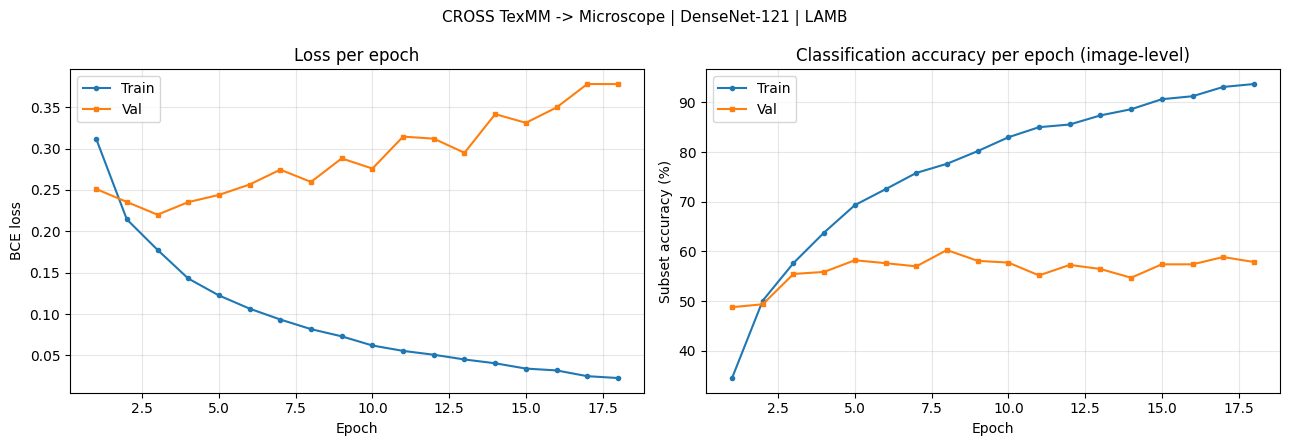

In [ ]:
ep = range(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ep, history['train_loss'], 'o-', ms=3, label='Train')
axes[0].plot(ep, history['val_loss'],   's-', ms=3, label='Val')
axes[0].set_title('Loss per epoch'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('BCE loss')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(ep, [a * 100 for a in history['train_acc']], 'o-', ms=3, label='Train')
axes[1].plot(ep, [a * 100 for a in history['val_acc']],   's-', ms=3, label='Val')
axes[1].set_title('Classification accuracy per epoch (image-level)')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Subset accuracy (%)')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.suptitle(RUN_NAME, fontsize=11); plt.tight_layout()
plt.savefig('/content/curves.png', dpi=150, bbox_inches='tight'); plt.show()

## 14 · Save artefacts to Drive

In [ ]:
os.makedirs(SAVE_DIR, exist_ok=True)
saved = []
for src, dst in [(CKPT_PATH, RUN_TAG + '.pt'),
                 ('/content/curves.png', RUN_TAG + '_curves.png'),
                 ('/content/per_class_f1.png', RUN_TAG + '_per_class_f1.png')]:
    if os.path.exists(src):
        shutil.copy(src, os.path.join(SAVE_DIR, dst)); saved.append(dst)
print('Saved to', SAVE_DIR, '->', saved)

Saved to /content/drive/MyDrive/Microscope_Images_Dataset -> ['cross_texmm_to_micro_densenet121_hires448_cosine.pt', 'cross_texmm_to_micro_densenet121_hires448_cosine_curves.png', 'cross_texmm_to_micro_densenet121_hires448_cosine_per_class_f1.png']
